# LAB2 — NLP : Classification de SMS (Spam Detection)

**Objectif du TP :** comparer plusieurs représentations textuelles — Bag of Words (BoW), Term Frequency (TF), TF-IDF et N-grammes — pour classer des SMS en deux catégories : `ham` (message légitime) et `spam` (message indésirable).



## 2. Importation des bibliothèques

- `pandas` et `numpy` : manipulation des données.
- `matplotlib` et `seaborn` : visualisations.
- `scikit-learn` : séparation des données, représentations textuelles, modèle et métriques.
- `PorterStemmer` : racinisation des mots anglais sans téléchargement de corpus NLTK.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 3. Chargement du dataset

**Dataset choisi : SMS Spam Collection.** La version Kaggle courante est souvent nommée `spam.csv`, avec les colonnes `v1` (étiquette) et `v2` (texte du SMS). La cellule reconnaît aussi les noms `label`/`message` et le fichier original `SMSSpamCollection`.

Téléchargement Kaggle : [SMS Spam Collection Dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset).

Si le fichier n'est pas dans le dossier du notebook, placez-le à cet endroit ou modifiez `DATA_PATH`.

In [3]:
DATA_PATH = Path("spam.csv")  

if DATA_PATH.exists():
    # La version Kaggle CSV est parfois encodée en latin-1 et contient des colonnes inutiles.
    df_raw = pd.read_csv(DATA_PATH, encoding="latin-1")
elif Path("SMSSpamCollection").exists():
    # Fichier original UCI : deux colonnes séparées par une tabulation, sans en-tête.
    df_raw = pd.read_csv(
        "SMSSpamCollection", sep="\t", header=None,
        names=["label", "message"], encoding="utf-8"
    )
else:
    raise FileNotFoundError(
        "Fichier introuvable. Téléchargez spam.csv depuis Kaggle et placez-le "
        "dans le même dossier que le notebook, ou modifiez DATA_PATH."
    )

print("Dimensions initiales :", df_raw.shape)
display(df_raw.head())
print("\nColonnes disponibles :", df_raw.columns.tolist())

Dimensions initiales : (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN



Colonnes disponibles : ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


## 4. Nettoyage de la structure et identification des colonnes

On standardise les deux colonnes nécessaires :
- `label` : classe à prédire (`ham` ou `spam`) ;
- `message` : contenu textuel du SMS.

Les colonnes supplémentaires parfois présentes dans le CSV Kaggle sont ignorées.

In [4]:
# Détecter automatiquement les colonnes les plus courantes.
lower_to_original = {str(c).strip().lower(): c for c in df_raw.columns}

if "v1" in lower_to_original and "v2" in lower_to_original:
    label_col, text_col = lower_to_original["v1"], lower_to_original["v2"]
elif "label" in lower_to_original and "message" in lower_to_original:
    label_col, text_col = lower_to_original["label"], lower_to_original["message"]
elif "category" in lower_to_original and "message" in lower_to_original:
    label_col, text_col = lower_to_original["category"], lower_to_original["message"]
else:
    raise ValueError(
        "Colonnes non reconnues. Colonnes trouvées : "
        + str(df_raw.columns.tolist())
        + ". Il faut une colonne d'étiquette et une colonne de texte."
    )

df = df_raw[[label_col, text_col]].copy()
df.columns = ["label", "message"]

# Supprimer les vraies valeurs manquantes avant la conversion en texte.
df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[(df["message"] != "") & (df["label"] != "")]
df = df[df["label"].isin(["ham", "spam"])].drop_duplicates().reset_index(drop=True)

print("Dimensions après nettoyage :", df.shape)
print("Nombre de messages :", len(df))
print("Nombre de classes :", df["label"].nunique())
print("Classes :", sorted(df["label"].unique()))
display(df.head())

Dimensions après nettoyage : (5158, 2)
Nombre de messages : 5158
Nombre de classes : 2
Classes : ['ham', 'spam']


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 5. Exploration du dataset (EDA)

Cette étape permet de comprendre les données avant l'entraînement : nombre de SMS, répartition des classes et exemples de messages.

In [5]:
print("Nombre total de SMS :", len(df))
print("\nNombre de SMS par classe :")
display(df["label"].value_counts().rename_axis("classe").to_frame("nombre"))

print("\nExemples ham :")
display(df[df["label"] == "ham"][["label", "message"]].head(3))
print("\nExemples spam :")
display(df[df["label"] == "spam"][["label", "message"]].head(3))

Nombre total de SMS : 5158

Nombre de SMS par classe :


,nombre
classe,
ham,4516
spam,642



Exemples ham :


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...



Exemples spam :


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
8,spam,WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 090617014...


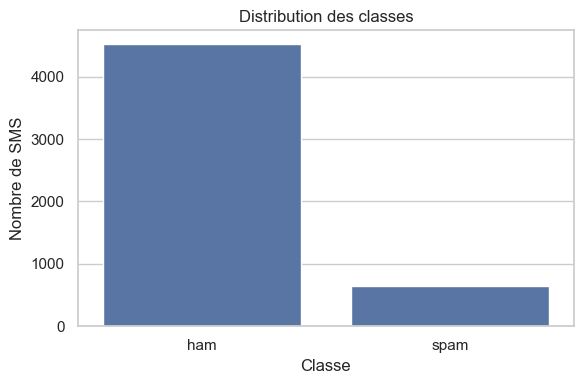

Pourcentage par classe :


,pourcentage (%)
label,
ham,87.55
spam,12.45


In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="label", order=["ham", "spam"])
ax.set_title("Distribution des classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de SMS")
plt.tight_layout()
plt.show()

class_percent = (df["label"].value_counts(normalize=True) * 100).round(2)
print("Pourcentage par classe :")
display(class_percent.rename("pourcentage (%)").to_frame())

### 5.1 Longueur des messages

La longueur est calculée en nombre de mots. Ce graphique aide à observer si les SMS spam et ham ont des longueurs différentes. Cette observation ne suffit pas, à elle seule, à classifier les messages.

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,14.13,11.12,1.0,7.0,11.0,18.0,171.0
spam,642.0,23.64,6.01,2.0,21.0,25.0,28.0,35.0


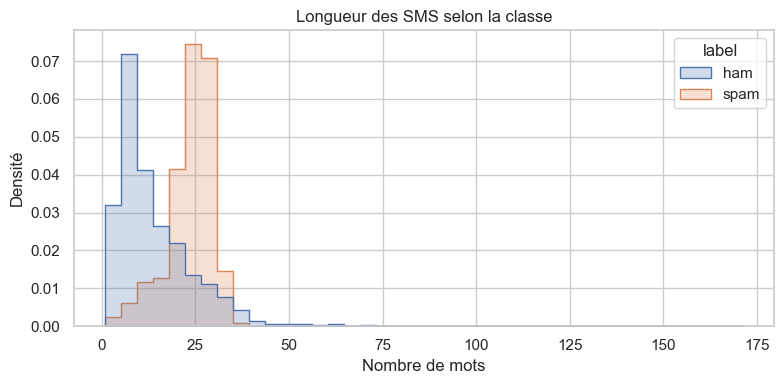

In [6]:
df["word_count"] = df["message"].apply(lambda x: len(x.split()))
display(df.groupby("label")["word_count"].describe().round(2))


plt.figure(figsize=(8, 4))
sns.histplot(
    data=df, x="word_count", hue="label",
    bins=40, element="step", stat="density", common_norm=False
)
plt.title("Longueur des SMS selon la classe")
plt.xlabel("Nombre de mots")
plt.ylabel("Densité")
plt.tight_layout()
plt.show()

### 5.2 Fiche d'identité du dataset

| Élément demandé | Valeur |
|---|---|
| Nom | SMS Spam Collection |
| Tâche | Classification binaire de SMS |
| Classes | `ham` et `spam` |
| Colonne texte | `message` |
| Colonne cible | `label` |
| Source | Kaggle (dataset dérivé de la collection SMS Spam Collection) |

Le nombre exact de documents et la répartition par classe sont calculés à partir du fichier chargé, car ils dépendent de la version du fichier.

## 6. Prétraitement du texte

Le prétraitement standardise le texte avant de le convertir en vecteurs numériques :
1. mettre le texte en minuscules ;
2. remplacer les URL et adresses e-mail par des marqueurs ;
3. tokeniser le texte ;
4. retirer les mots vides anglais (*stop words*) ;
5. appliquer le stemming avec PorterStemmer.

**Important :** les messages sont séparés en apprentissage et test avant l'entraînement des représentations. Le modèle ne voit donc pas les étiquettes du jeu de test pendant l'apprentissage.

In [7]:
stemmer = PorterStemmer()
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " emailtoken ", text)
    # Conserver lettres et chiffres : les nombres peuvent être informatifs dans les SMS.
    tokens = re.findall(r"[a-z]+|\d+", text)
    processed = []
    for token in tokens:
        if token in {"urltoken", "emailtoken"}:
            processed.append(token)
        elif token not in stop_words and len(token) > 1:
            processed.append(stemmer.stem(token))
    return " ".join(processed)

df["clean_message"] = df["message"].apply(preprocess_text)
display(df[["message", "clean_message", "label"]].head(8))

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",jurong point crazi avail bugi great world la buffet cine got amor wat,ham
1,Ok lar... Joking wif u oni...,ok lar joke wif oni,ham
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entri wkli comp win fa cup final tkt 21 st 2005 text fa 87121 receiv entri question std txt rate appli 08452810...,spam
3,U dun say so early hor... U c already then say...,dun say earli hor say,ham
4,"Nah I don't think he goes to usf, he lives around here though",nah don think goe usf live,ham
5,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,freemsg hey darl week word like fun tb ok xxx std chg send 50 rcv,spam
6,Even my brother is not like to speak with me. They treat me like aids patent.,brother like speak treat like aid patent,ham
7,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...,request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun,ham


### 6.1 Comprendre les étapes de prétraitement

Cette petite démonstration rend les étapes visibles séparément : tokenisation, suppression des stop words et stemming. La fonction complète ci-dessus applique ces opérations automatiquement à tous les messages.

In [8]:
example_text = df.loc[0, "message"]
example_lower = example_text.lower()
example_tokens = re.findall(r"[a-z]+|\d+", example_lower)
example_without_stopwords = [
    tok for tok in example_tokens
    if tok not in stop_words and len(tok) > 1
]
example_stemmed = [stemmer.stem(tok) for tok in example_without_stopwords]

print("Texte original :\n", example_text)
print("\nTokens :\n", example_tokens)
print("\nAprès suppression des stop words :\n", example_without_stopwords)
print("\nAprès stemming :\n", example_stemmed)

Texte original :
 Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Tokens :
 ['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'there', 'got', 'amore', 'wat']

Après suppression des stop words :
 ['jurong', 'point', 'crazy', 'available', 'bugis', 'great', 'world', 'la', 'buffet', 'cine', 'got', 'amore', 'wat']

Après stemming :
 ['jurong', 'point', 'crazi', 'avail', 'bugi', 'great', 'world', 'la', 'buffet', 'cine', 'got', 'amor', 'wat']


## 7. Préparation des jeux d'apprentissage et de test

On utilise une séparation stratifiée de 80 % pour l'entraînement et 20 % pour le test. `stratify=y` conserve approximativement la même proportion de `ham` et de `spam` dans les deux parties.

Le même découpage et le même classifieur sont réutilisés pour toutes les expériences afin de comparer les représentations de façon plus juste.

In [9]:
X = df["clean_message"].fillna("")
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Taille entraînement :", len(X_train))
print("Taille test :", len(X_test))
print("\nRépartition entraînement :")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nRépartition test :")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Taille entraînement : 4126
Taille test : 1032

Répartition entraînement :


,proportion
label,
ham,0.875424
spam,0.124576



Répartition test :


,proportion
label,
ham,0.875969
spam,0.124031


In [10]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train.to_frame(name="text"),
    y_train
)

X_train_balanced = X_train_balanced["text"]

print("Après rééquilibrage :")
print(y_train_balanced.value_counts())

Après rééquilibrage :
label
ham     3612
spam    3612
Name: count, dtype: int64


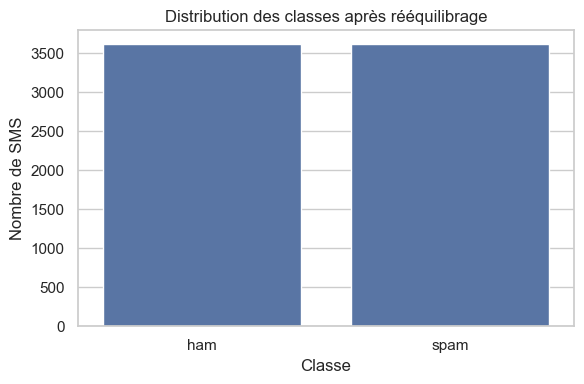

Pourcentage par classe après rééquilibrage :


,pourcentage (%)
label,
ham,50.0
spam,50.0


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_balanced = pd.DataFrame({
    "text": X_train_balanced,
    "label": y_train_balanced
})

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_balanced, x="label", order=["ham", "spam"])
ax.set_title("Distribution des classes après rééquilibrage")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre de SMS")
plt.tight_layout()
plt.show()

class_percent = (
    df_balanced["label"].value_counts(normalize=True) * 100
).round(2)

print("Pourcentage par classe après rééquilibrage :")
display(class_percent.rename("pourcentage (%)").to_frame())

## 8. Fonctions d'entraînement et d'évaluation

Chaque expérience suit les mêmes étapes :
1. construire la représentation à partir du texte d'entraînement ;
2. transformer le texte de test avec la représentation déjà ajustée ;
3. entraîner une régression logistique ;
4. afficher Accuracy, Precision, Recall, F1-score, rapport de classification et matrice de confusion.

On prend `spam` comme classe positive pour la précision, le rappel et le F1-score. Le rappel spam est particulièrement important, car un rappel faible signifie que des SMS indésirables ne sont pas détectés.

In [13]:
results = {}
trained_models = {}

def evaluate_experiment(name, vectorizer):

    # Vectorisation : apprentissage du vocabulaire sur l'entraînement équilibré
    Xtr = vectorizer.fit_transform(X_train_balanced)

    # Transformation du test sans réapprendre le vocabulaire
    Xte = vectorizer.transform(X_test)

    model = LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=RANDOM_STATE
    )

    # Entraînement sur les labels rééquilibrés
    model.fit(Xtr, y_train_balanced)

    # Prédictions sur le test original
    y_pred = model.predict(Xte)

    metrics = {
        "Méthode": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall (spam)": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-score (spam)": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Nombre de caractéristiques": Xtr.shape[1]
    }

    results[name] = metrics

    trained_models[name] = {
        "vectorizer": vectorizer,
        "model": model,
        "y_pred": y_pred,
        "X_test_vectorized": Xte
    }

    print("=" * 60)
    print(f"RÉSULTATS — {name}")
    print("=" * 60)

    for metric, value in metrics.items():
        if isinstance(value, (int, float)):
            print(f"{metric} : {value:.4f}" if isinstance(value, float)
                  else f"{metric} : {value}")

    print("\nRapport de classification :")
    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0,
        digits=4
    ))

    cm = confusion_matrix(
        y_test, y_pred, labels=["ham", "spam"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["ham", "spam"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion — {name}")
    plt.tight_layout()
    plt.show()

    return metrics

## 9. Expérience 1 — Bag of Words (BoW)

**Principe :** chaque SMS est représenté par le nombre d'occurrences des mots du vocabulaire. L'ordre des mots n'est pas conservé. On limite le vocabulaire aux 20 000 termes les plus fréquents pour garder un modèle raisonnable.

RÉSULTATS — BoW (comptages)
Accuracy : 0.9874
Precision (spam) : 0.9832
Recall (spam) : 0.9141
F1-score (spam) : 0.9474
Nombre de caractéristiques : 5902

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9880    0.9978    0.9928       904
        spam     0.9832    0.9141    0.9474       128

    accuracy                         0.9874      1032
   macro avg     0.9856    0.9559    0.9701      1032
weighted avg     0.9874    0.9874    0.9872      1032



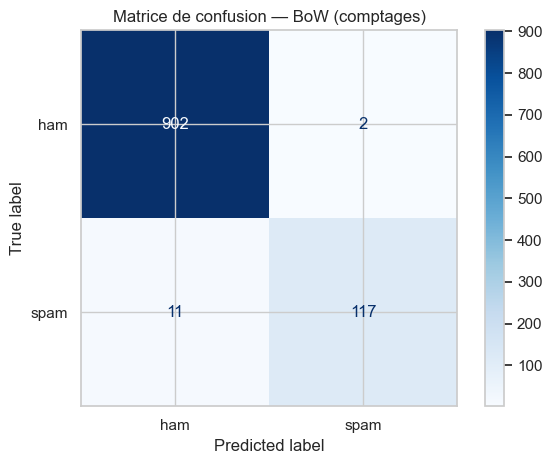

In [15]:
bow_vectorizer = CountVectorizer(
    max_features=20000,
    ngram_range=(1, 1)
)

bow_metrics = evaluate_experiment(
    "BoW (comptages)",
    bow_vectorizer
)

 Analyse de l'expérience 1 :Le modèle BoW obtient une accuracy de 98,74 % et un F1-score de 94,74 % pour la classe spam. Il classe correctement 902 SMS ham et 117 SMS spam, avec seulement 2 faux positifs et 11 faux négatifs. Ces résultats montrent que BoW est performant, mais certains spams ne sont pas détectés. Il faut comparer ces résultats à ceux de TF, TF-IDF et des n-grammes pour identifier la meilleure représentation.

## 10. Expérience 2 — Term Frequency (TF)

**Principe :** on utilise les fréquences normalisées des termes plutôt que les comptes bruts. Ici, `use_idf=False` désactive la pondération IDF et `norm="l1"` normalise les poids de chaque message.

RÉSULTATS — TF (fréquences normalisées)
Accuracy : 0.9583
Precision (spam) : 0.7815
Recall (spam) : 0.9219
F1-score (spam) : 0.8459
Nombre de caractéristiques : 5902

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9886    0.9635    0.9759       904
        spam     0.7815    0.9219    0.8459       128

    accuracy                         0.9583      1032
   macro avg     0.8851    0.9427    0.9109      1032
weighted avg     0.9630    0.9583    0.9598      1032



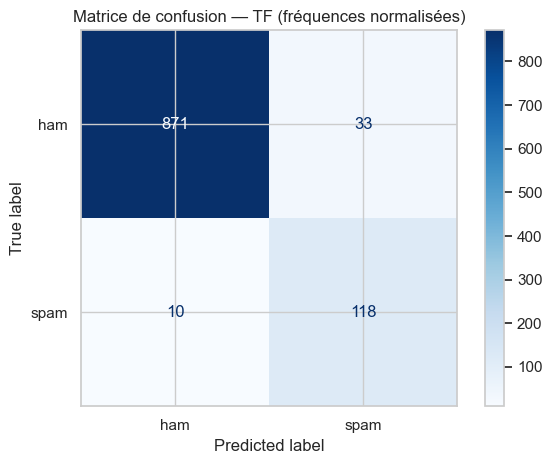

In [17]:
tf_vectorizer = TfidfVectorizer(
    use_idf=False, norm="l1", max_features=20000, ngram_range=(1, 1)
)
tf_metrics = evaluate_experiment("TF (fréquences normalisées)", tf_vectorizer)

**Analyse de l'expérience 2 :** comparez ses métriques à celles de BoW. Les fréquences normalisées réduisent l'effet de la longueur totale du message, alors que BoW conserve les comptes d'occurrences.

## 11. Expérience 3 — TF-IDF

**Principe :** TF-IDF augmente le poids des termes fréquents dans un SMS mais moins fréquents dans l'ensemble du corpus, et réduit le poids des mots présents presque partout.

RÉSULTATS — TF-IDF (unigrammes)
Accuracy : 0.9855
Precision (spam) : 0.9520
Recall (spam) : 0.9297
F1-score (spam) : 0.9407
Nombre de caractéristiques : 5902

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9901    0.9934    0.9917       904
        spam     0.9520    0.9297    0.9407       128

    accuracy                         0.9855      1032
   macro avg     0.9710    0.9615    0.9662      1032
weighted avg     0.9854    0.9855    0.9854      1032



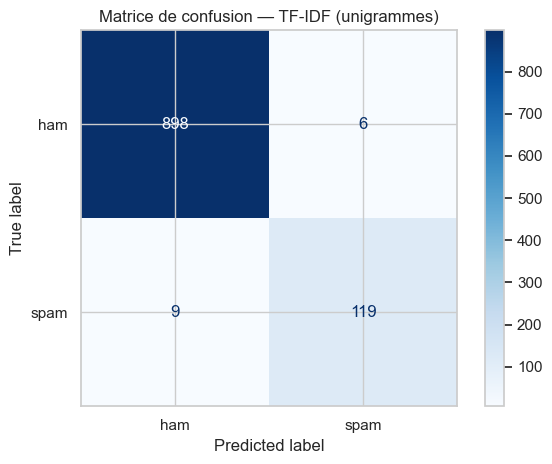

In [18]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=20000, ngram_range=(1, 1), sublinear_tf=True
)
tfidf_metrics = evaluate_experiment("TF-IDF (unigrammes)", tfidf_vectorizer)

**Analyse de l'expérience 3 :** TF détecte davantage de spams que BoW, mais classe plus de messages légitimes à tort comme spam. Son rappel est meilleur, mais son F1-score spam est inférieur à celui de BoW

## 12. Expérience 4 — N-grammes

Un *unigramme* est un mot seul, un *bigramme* une séquence de deux mots et un *trigramme* une séquence de trois mots. Les n-grammes peuvent conserver une partie du contexte, par exemple une expression comme « claim your prize ». Chaque configuration est entraînée et évaluée séparément.

### 12.1 Unigrammes

RÉSULTATS — N-grammes — unigrammes
Accuracy : 0.9874
Precision (spam) : 0.9832
Recall (spam) : 0.9141
F1-score (spam) : 0.9474
Nombre de caractéristiques : 5902

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9880    0.9978    0.9928       904
        spam     0.9832    0.9141    0.9474       128

    accuracy                         0.9874      1032
   macro avg     0.9856    0.9559    0.9701      1032
weighted avg     0.9874    0.9874    0.9872      1032



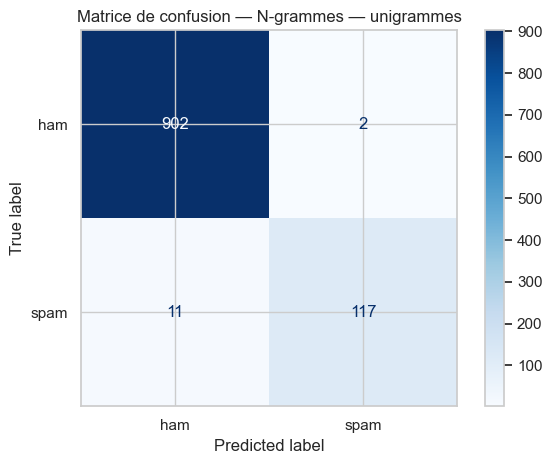

In [20]:
unigram_vectorizer = CountVectorizer(max_features=20000, ngram_range=(1, 1))
unigram_metrics = evaluate_experiment("N-grammes — unigrammes", unigram_vectorizer)

les résultats sont identiques à ceux de BoW, car les deux représentations utilisent les occurrences de mots seuls, sans tenir compte de l’ordre des mots

### 12.2 Bigrammes

RÉSULTATS — N-grammes — bigrammes
Accuracy : 0.9593
Precision (spam) : 1.0000
Recall (spam) : 0.6719
F1-score (spam) : 0.8037
Nombre de caractéristiques : 22907

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9556    1.0000    0.9773       904
        spam     1.0000    0.6719    0.8037       128

    accuracy                         0.9593      1032
   macro avg     0.9778    0.8359    0.8905      1032
weighted avg     0.9611    0.9593    0.9558      1032



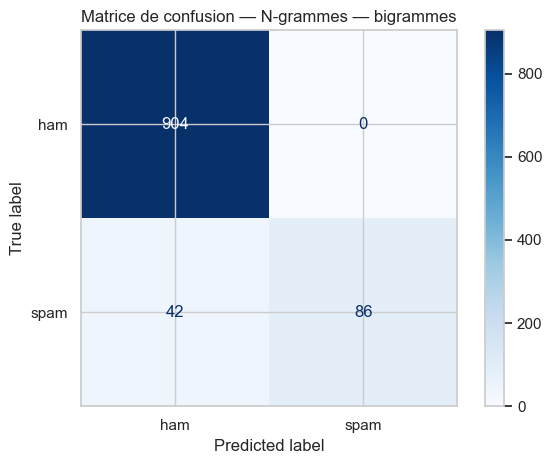

In [21]:
bigram_vectorizer = CountVectorizer(max_features=30000, ngram_range=(2, 2))
bigram_metrics = evaluate_experiment("N-grammes — bigrammes", bigram_vectorizer)

le modèle ne classe aucun SMS légitime comme spam, mais il laisse passer 41 SMS indésirables. Malgré sa précision parfaite, son rappel est faible : les bigrammes seuls ne détectent pas suffisamment de spams.

### 12.3 Trigrammes

RÉSULTATS — N-grammes — trigrammes
Accuracy : 0.9351
Precision (spam) : 1.0000
Recall (spam) : 0.4766
F1-score (spam) : 0.6455
Nombre de caractéristiques : 22325

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9310    1.0000    0.9643       904
        spam     1.0000    0.4766    0.6455       128

    accuracy                         0.9351      1032
   macro avg     0.9655    0.7383    0.8049      1032
weighted avg     0.9396    0.9351    0.9247      1032



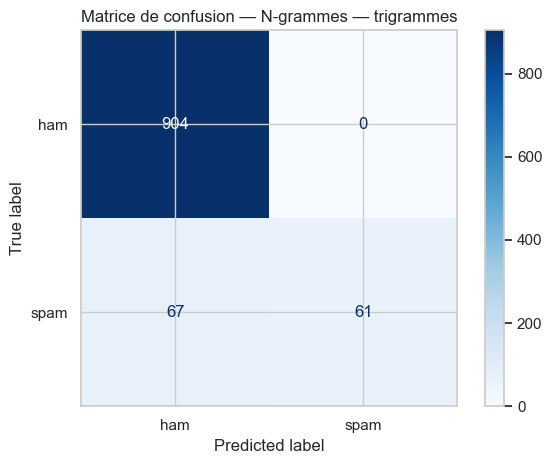

In [22]:
trigram_vectorizer = CountVectorizer(max_features=30000, ngram_range=(3, 3))
trigram_metrics = evaluate_experiment("N-grammes — trigrammes", trigram_vectorizer)

le modèle ne classe aucun SMS légitime comme spam, mais il manque plus de la moitié des spams. Les trigrammes seuls sont donc moins performants que les unigrammes, car ils représentent des séquences plus spécifiques et moins fréquentes.

### 12.4 Combinaison unigrammes + bigrammes + trigrammes

RÉSULTATS — N-grammes — 1 à 3
Accuracy : 0.9864
Precision (spam) : 0.9914
Recall (spam) : 0.8984
F1-score (spam) : 0.9426
Nombre de caractéristiques : 40000

Rapport de classification :
              precision    recall  f1-score   support

         ham     0.9858    0.9989    0.9923       904
        spam     0.9914    0.8984    0.9426       128

    accuracy                         0.9864      1032
   macro avg     0.9886    0.9487    0.9675      1032
weighted avg     0.9865    0.9864    0.9861      1032



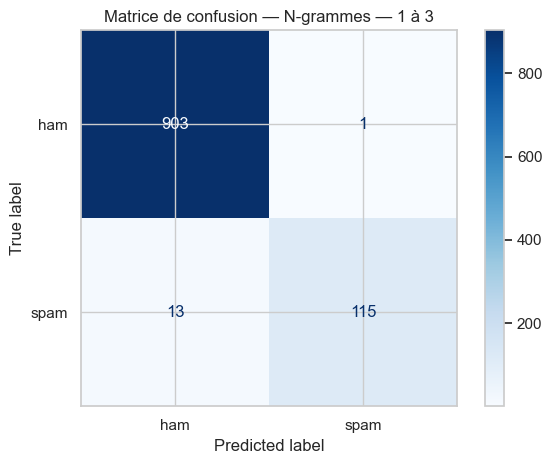

In [23]:
ngram_vectorizer = CountVectorizer(max_features=40000, ngram_range=(1, 3))
ngram_metrics = evaluate_experiment("N-grammes — 1 à 3", ngram_vectorizer)

**Analyse des n-grammes :** le modèle est performant, mais il ne dépasse pas les unigrammes seuls. L’ajout de bigrammes et de trigrammes n’améliore donc pas les résultats dans cette expérience.

## 13. Comparaison générale des expériences

Cette cellule regroupe les résultats obtenus séparément. Elle trie les méthodes par F1-score de la classe `spam`, puis affiche un graphique pour faciliter la discussion.

,Méthode,Accuracy,Precision (spam),Recall (spam),F1-score (spam),Nombre de caractéristiques
0,BoW (comptages),0.9874,0.9832,0.9141,0.9474,5902
1,N-grammes — unigrammes,0.9874,0.9832,0.9141,0.9474,5902
2,N-grammes — 1 à 3,0.9864,0.9914,0.8984,0.9426,40000
3,TF-IDF (unigrammes),0.9855,0.9520,0.9297,0.9407,5902
4,TF (fréquences normalisées),0.9583,0.7815,0.9219,0.8459,5902
5,N-grammes — bigrammes,0.9593,1.0000,0.6719,0.8037,22907
6,N-grammes — trigrammes,0.9351,1.0000,0.4766,0.6455,22325


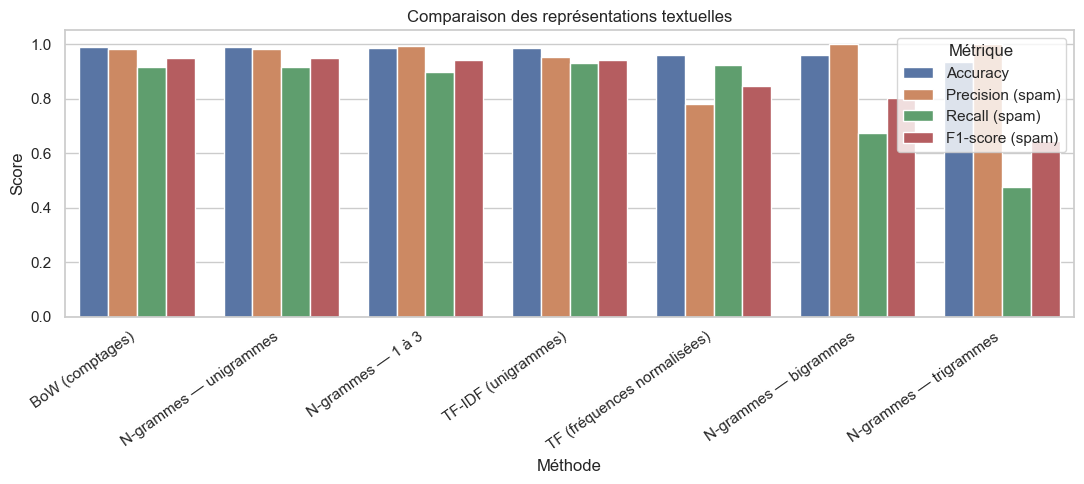

Meilleure méthode selon le F1-score spam : BoW (comptages)
F1-score spam : 0.9474


In [24]:
comparison = pd.DataFrame(list(results.values()))
comparison = comparison.sort_values("F1-score (spam)", ascending=False).reset_index(drop=True)
display(comparison.round(4))

plt.figure(figsize=(11, 5))
plot_data = comparison.melt(
    id_vars="Méthode",
    value_vars=["Accuracy", "Precision (spam)", "Recall (spam)", "F1-score (spam)"],
    var_name="Métrique", value_name="Score"
)
sns.barplot(data=plot_data, x="Méthode", y="Score", hue="Métrique")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.title("Comparaison des représentations textuelles")
plt.tight_layout()
plt.show()

best_name = comparison.iloc[0]["Méthode"]
print("Meilleure méthode selon le F1-score spam :", best_name)
print("F1-score spam :", round(comparison.iloc[0]["F1-score (spam)"], 4))

## 14. Analyse détaillée du meilleur modèle

Le meilleur modèle est choisi selon le F1-score de la classe `spam`, car cette métrique tient compte à la fois de la précision et du rappel. Cette règle de sélection est définie avant de commenter les résultats.

In [25]:
best = trained_models[best_name]
best_pred = best["y_pred"]

print("Méthode retenue :", best_name)
print(classification_report(
    y_test, best_pred, labels=["ham", "spam"], zero_division=0, digits=4
))

cm = confusion_matrix(y_test, best_pred, labels=["ham", "spam"])
print("Matrice de confusion (lignes = vraies classes, colonnes = prédictions) :")
display(pd.DataFrame(
    cm,
    index=["Réel ham", "Réel spam"],
    columns=["Prédit ham", "Prédit spam"]
))

Méthode retenue : BoW (comptages)
              precision    recall  f1-score   support

         ham     0.9880    0.9978    0.9928       904
        spam     0.9832    0.9141    0.9474       128

    accuracy                         0.9874      1032
   macro avg     0.9856    0.9559    0.9701      1032
weighted avg     0.9874    0.9874    0.9872      1032

Matrice de confusion (lignes = vraies classes, colonnes = prédictions) :


,Prédit ham,Prédit spam
Réel ham,902,2
Réel spam,11,117


## 15. Analyse des erreurs du meilleur modèle

Cette cellule affiche quelques messages mal classés. Elle permet de discuter des erreurs réelles : vocabulaire ambigu, abréviations, liens, messages très courts ou expressions inconnues. Les exemples doivent être interprétés avec prudence : quelques cas ne suffisent pas à établir une règle générale.

In [26]:
error_df = pd.DataFrame({
    "message_original": df.loc[X_test.index, "message"].values,
    "texte_pretraite": X_test.values,
    "vraie_classe": y_test.values,
    "classe_predite": best_pred
})
errors = error_df[error_df["vraie_classe"] != error_df["classe_predite"]]
print("Nombre d'erreurs :", len(errors), "sur", len(error_df), "messages de test")
display(errors.head(15))

Nombre d'erreurs : 13 sur 1032 messages de test


,message_original,texte_pretraite,vraie_classe,classe_predite
168,"Storming msg: Wen u lift d phne, u say \HELLO\"" Do u knw wt is d real meaning of HELLO?? . . . It's d name of a girl...",storm msg wen lift phne say hello knw wt real mean hello girl ye knw dat girl margaret hello girlfrnd grahmbel invnt...,ham,spam
205,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,sorri miss let talk time 07090201529,spam,ham
299,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better...",lookatm thank purchas video clip lookatm ve charg 35 think better send video mmsto 32323,spam,ham
389,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,babe want dont babi im nasti thing filthyguy fanci rude time sexi bitch slo hard txt xxx slo msg,spam,ham
434,"\For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit www.shortbreaks.org.uk\""""",sparkl shop break 45 person 0121 2025050 visit urltoken,spam,ham
551,Adult 18 Content Your video will be with you shortly,adult 18 content video shortli,spam,ham
799,I'm always on yahoo messenger now. Just send the message to me and i.ll get it you may have to send it in the mobile...,yahoo messeng just send messag ll send mobil mode sha ll repli,ham,spam
835,Monthly password for wap. mobsi.com is 391784. Use your wap phone not PC.,monthli password wap mobsi com 391784 use wap phone pc,spam,ham
848,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do yo...,date start sent text talk sport radio week connect think coincid,spam,ham
863,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,guess time creat web page urltoken read wrote wait opinion want friend,spam,ham


## 16. Tester le modèle sur de nouveaux SMS

Remplacez les exemples par vos propres messages. Le modèle choisi est réutilisé avec le vectoriseur entraîné sur les données d'apprentissage ; il ne faut pas réajuster le vectoriseur sur les nouveaux messages.

In [42]:

# Tester le modèle avec un SMS saisi par l'utilisateur

message = input("Saisissez votre SMS : ")

# Prétraitement du texte
message_clean = preprocess_text(message)


# Transformation avec le vectoriseur du meilleur modèle
message_vector = best["vectorizer"].transform([message_clean])

# Prédiction
prediction = best["model"].predict(message_vector)[0]

# Affichage du résultat
print("\nSMS saisi :", message)
print("Prédiction :", prediction.upper())

if prediction == "spam":
    print("⚠️ Ce message est probablement un SPAM.")
else:
    print("✅ Ce message est probablement un message légitime (HAM).")


Saisissez votre SMS :  URGENT! Your bank account has been suspended. Verify your details immediately: www.fake-bank.com



SMS saisi : URGENT! Your bank account has been suspended. Verify your details immediately: www.fake-bank.com
Prédiction : SPAM
⚠️ Ce message est probablement un SPAM.


## 17. Conclusion et discussion 





Dans ce TP, nous avons comparé plusieurs représentations textuelles pour la classification des SMS en deux catégories : `ham` et `spam`. Les résultats montrent que **BoW et les unigrammes sont les méthodes les plus performantes**, avec une accuracy de 98,74 % et un F1-score spam de 94,74 %. TF-IDF et la combinaison de n-grammes de 1 à 3 obtiennent également de bons résultats, tandis que les bigrammes et les trigrammes seuls détectent moins efficacement les spams.

Cette comparaison montre que l’ajout de séquences de plusieurs mots n’améliore pas systématiquement la classification. Dans notre expérience, les unigrammes offrent le meilleur compromis entre précision et rappel. Enfin, le prétraitement et le choix de la représentation textuelle jouent un rôle important dans les performances du modèle. Pour aller plus loin, nous pourrions tester d’autres classifieurs, ajuster leurs paramètres et comparer différentes stratégies de traitement du déséquilibre des classes.